<a href="https://colab.research.google.com/github/matt-ritton/ml.hotel-booking-demand/blob/main/hotel_booking_demand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning: Hotel Booking Demand

Project for the Introduction to Statistical Learning course.

**Dataset:** https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand/data

Original article:
```
Nuno Antonio, Ana de Almeida, Luis Nunes,
Hotel booking demand datasets,
Data in Brief,
Volume 22,
2019,
Pages 41-49,
ISSN 2352-3409,
https://doi.org/10.1016/j.dib.2018.11.126.
(https://www.sciencedirect.com/science/article/pii/S2352340918315191)
```



# Dependencies

In [1]:
options(
  repos = c(CRAN = "https://packagemanager.posit.co/cran/__linux__/noble/latest"),
  HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
                          paste(getRversion(), R.version["platform"],
                                R.version["arch"], R.version["os"]))
)
install.packages(c("caret"))
install.packages("randomForest")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘plyr’, ‘recipes’, ‘reshape2’, ‘yardstick’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(caret)
library(ggplot2)
library(MASS)
library(randomForest)

Loading required package: ggplot2

Loading required package: lattice

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin




## Dataset

In [3]:
hotel <- read.csv("https://raw.githubusercontent.com/matt-ritton/ml.hotel-booking-demand/main/Hotel.csv",
                  na.strings = c("NA", "NULL", ""))
str(hotel)

'data.frame':	119390 obs. of  32 variables:
 $ hotel                         : chr  "Resort Hotel" "Resort Hotel" "Resort Hotel" "Resort Hotel" ...
 $ is_canceled                   : int  0 0 0 0 0 0 0 0 1 1 ...
 $ lead_time                     : int  342 737 7 13 14 14 0 9 85 75 ...
 $ arrival_date_year             : int  2015 2015 2015 2015 2015 2015 2015 2015 2015 2015 ...
 $ arrival_date_month            : chr  "July" "July" "July" "July" ...
 $ arrival_date_week_number      : int  27 27 27 27 27 27 27 27 27 27 ...
 $ arrival_date_day_of_month     : int  1 1 1 1 1 1 1 1 1 1 ...
 $ stays_in_weekend_nights       : int  0 0 0 0 0 0 0 0 0 0 ...
 $ stays_in_week_nights          : int  0 0 1 1 2 2 2 2 3 3 ...
 $ adults                        : int  2 2 1 1 2 2 2 2 2 2 ...
 $ children                      : int  0 0 0 0 0 0 0 0 0 0 ...
 $ babies                        : int  0 0 0 0 0 0 0 0 0 0 ...
 $ meal                          : chr  "BB" "BB" "BB" "BB" ...
 $ country                 

In [4]:
# Target variable analysis

## Number of records
c_data <- table(hotel$is_canceled)
names(c_data) <- c("False", "True")
c_data

cat("\n")
## Class balance
tab <- prop.table(c_data)
tab

## Class balance by hotel type
c_type <- prop.table(table(hotel$hotel, hotel$is_canceled), margin = 1)
colnames(c_type) <- c("False", "True")
c_type

## Checking which cases the target variable treats as canceled
cases_tab <- table(hotel$reservation_status, hotel$is_canceled)
colnames(cases_tab) <- c("False", "True")
cases_tab

False  True 
75166 44224 

    False      True 
0.6295837 0.3704163 

              
                   False      True
  City Hotel   0.5827304 0.4172696
  Resort Hotel 0.7223665 0.2776335

           
            False  True
  Canceled      0 43017
  Check-Out 75166     0
  No-Show       0  1207

In [5]:
summary(hotel)

       hotel         is_canceled       lead_time   arrival_date_year
 Length   :119390   Min.   :0.0000   Min.   :  0   Min.   :2015     
 N.unique :     2   1st Qu.:0.0000   1st Qu.: 18   1st Qu.:2016     
 N.blank  :     0   Median :0.0000   Median : 69   Median :2016     
 Min.nchar:    10   Mean   :0.3704   Mean   :104   Mean   :2016     
 Max.nchar:    12   3rd Qu.:1.0000   3rd Qu.:160   3rd Qu.:2017     
                    Max.   :1.0000   Max.   :737   Max.   :2017     
                                                                    
 arrival_date_month arrival_date_week_number arrival_date_day_of_month
 Length   :119390   Min.   : 1.00            Min.   : 1.0             
 N.unique :    12   1st Qu.:16.00            1st Qu.: 8.0             
 N.blank  :     0   Median :28.00            Median :16.0             
 Min.nchar:     3   Mean   :27.17            Mean   :15.8             
 Max.nchar:     9   3rd Qu.:38.00            3rd Qu.:23.0             
                    Ma

In [6]:
# Checking for missing values
na_count <- colSums(is.na(hotel))
cat(paste(names(na_count), na_count, sep = ": "), sep = "\n")

hotel: 0
is_canceled: 0
lead_time: 0
arrival_date_year: 0
arrival_date_month: 0
arrival_date_week_number: 0
arrival_date_day_of_month: 0
stays_in_weekend_nights: 0
stays_in_week_nights: 0
adults: 0
children: 4
babies: 0
meal: 0
country: 488
market_segment: 0
distribution_channel: 0
is_repeated_guest: 0
previous_cancellations: 0
previous_bookings_not_canceled: 0
reserved_room_type: 0
assigned_room_type: 0
booking_changes: 0
deposit_type: 0
agent: 16340
company: 112593
days_in_waiting_list: 0
customer_type: 0
adr: 0
required_car_parking_spaces: 0
total_of_special_requests: 0
reservation_status: 0
reservation_status_date: 0


In [7]:
# Checking for unjustified values

## Bookings with no guests
no_guests <- hotel$adults + hotel$children + hotel$babies == 0
cat("Bookings with no guests:", sum(no_guests, na.rm = TRUE))

## Bookings with no stays
no_stays <- hotel$stays_in_week_nights + hotel$stays_in_weekend_nights == 0
cat("\nBookings with no stays:", sum(no_stays, na.rm = TRUE))

Bookings with no guests: 180
Bookings with no stays: 715

In [8]:
# Checking occurrences

## Checking counts by reserved room type
cat("\nBookings by distribution channel:")
table(hotel$distribution_channel)

cat("\nBookings by room type:")
table(hotel$reserved_room_type)


Bookings by distribution channel:


Corporate    Direct       GDS     TA/TO Undefined 
     6677     14645       193     97870         5 


Bookings by room type:


    A     B     C     D     E     F     G     H     L     P 
85994  1118   932 19201  6535  2897  2094   601     6    12 

In [9]:
# Checking for data leakage

## Assigned Room Type: assigned room same as or different from the reserved one
room_match <- factor(hotel$reserved_room_type == hotel$assigned_room_type,
                     levels = c(TRUE, FALSE), labels = c("Same", "Different"))

cat("Assigned vs. reserved room:")
rooms <- table(Room = room_match, Canceled = hotel$is_canceled)
colnames(rooms) <- c("False", "True")
rooms

cat("\nAssigned vs. reserved room (proportion):")
rooms_p <- round(prop.table(table(Room = room_match, Canceled = hotel$is_canceled), margin = 1), 3)
colnames(rooms_p) <- c("False", "True")
rooms_p

## Parking spaces
parking <- factor(hotel$required_car_parking_spaces > 0,
                  levels = c(FALSE, TRUE), labels = c("No space", "With space"))

cat("\nParking space:")
parking_tab <- table(Parking = parking, Canceled = hotel$is_canceled)
colnames(parking_tab) <- c("False", "True")
parking_tab

cat("\nParking space (proportion):")
parking_p <- round(prop.table(table(Parking = parking, Canceled = hotel$is_canceled), margin = 1), 3)
colnames(parking_p) <- c("False", "True")
parking_p

Assigned vs. reserved room:

           Canceled
Room        False  True
  Same      61051 43422
  Different 14115   802


Assigned vs. reserved room (proportion):

           Canceled
Room        False  True
  Same      0.584 0.416
  Different 0.946 0.054


Parking space:

            Canceled
Parking      False  True
  No space   67750 44224
  With space  7416     0


Parking space (proportion):

            Canceled
Parking      False  True
  No space   0.605 0.395
  With space 1.000 0.000

## Data Preprocessing

In [10]:
hotel_new <- hotel

**Categorical Variables**

---
All CHR variables are converted to FACTOR. As for the unique values:

**Agents and Company:** NULL means "Not applicable". Therefore, a binary conversion is proposed for these variables: "No" for NULL values and "Yes" for non-NULL values (any linked ID).

**Country:** Given the large number of possible values, countries with a share below 1% or that are unknown are grouped into a single group (OTHERS - OTH).

**Meal**: Undefined and SC are essentially the same thing, so they are renamed to "NM" (No Meal).

In [11]:
# Categorical values

## Agent
hotel_new$agent <- factor(
  !is.na(hotel$agent),
  levels = c(FALSE, TRUE),
  labels = c("No", "Yes")
)

## Company
hotel_new$company <- factor(
  !is.na(hotel$company),
  levels = c(FALSE, TRUE),
  labels = c("No", "Yes")
)

## Country
countries_freq <- table(hotel_new$country)
relevant_countries <- names(countries_freq[countries_freq / nrow(hotel_new) >= 0.01])
hotel_new$country[
  is.na(hotel_new$country) | !(hotel_new$country %in% relevant_countries)
] <- "OTH"

## Meals
hotel_new$meal[
  hotel_new$meal %in% c("Undefined", "SC")
] <- "NM"

**Missing or Unjustified Data**

---
Cases with a negligible amount of missing data compared to the total, or with no logical justification, are removed:

**ADR**: there are 2 inconsistent records: a negative daily rate (-6.38) and a daily rate ten times higher than the second highest (5400).

**Children:** only 4 records are missing this variable.

**Bookings with no guests:** cases with no recorded guests (180) or no recorded stays (715).

In [12]:
# Missing or unjustified data

## ADR
hotel_new <- hotel_new[hotel_new$adr >= 0 & hotel_new$adr < 5000, ]

## Children
hotel_new <- hotel_new[!is.na(hotel_new$children),]

## No Guests
hotel_new <- hotel_new[
  (hotel_new$adults + hotel_new$children + hotel_new$babies != 0) &
  (hotel_new$stays_in_week_nights + hotel_new$stays_in_weekend_nights != 0),
]

**Very Rare Occurrences**

---
To avoid problems in training/testing due to missing data for a category, the following records are removed:

**Distribution Channel**: there is only 1 case of Undefined.

**Reserved Room Type**: there are only 6 cases of type L.

In [13]:
# Very rare occurrences

## Distribution Channel
hotel_new <- hotel_new[hotel_new$distribution_channel != "Undefined", ]

cat("\nBookings by distribution channel:")
table(hotel_new$distribution_channel)

## Reserved Room Type
hotel_new <- hotel_new[hotel_new$reserved_room_type != "L", ]

cat("\nBookings by room type:")
table(hotel_new$reserved_room_type)


Bookings by distribution channel:


Corporate    Direct       GDS     TA/TO 
     6584     14450       190     97334 


Bookings by room type:


    A     B     C     D     E     F     G     H 
85395  1106   923 19096  6482  2879  2074   597 

**Data Leakage**

---
Since the goal is to predict a cancellation BEFORE check-in, the following variables are removed to avoid leakage:

**Reservation Status, Reservation Status Date**: these variables represent the final status of the booking.

**Assigned Room Type**: set at check-in.

**Booking Changes:** counted up to check-in or cancellation.

**Required Car Parking Spaces**: none of the bookings with a parking space were canceled.

In [14]:
# Data leakage
cols_del <- c(
  "reservation_status",
  "reservation_status_date",
  "assigned_room_type",
  "booking_changes",
  "required_car_parking_spaces"
)

hotel_new[cols_del] <- NULL

**Seasonality and Generalization**

---
To assess the impact of seasonality and generalization, only Arrival Date Month is used as a date-related variable, for the following reasons:

**Arrival Date Year**: since the variable covers a fixed period, it should be disregarded for generalization purposes.

**Arrival Date Week Number**: redundant for seasonality.

**Arrival Date Day of Month**: low real impact.

In [15]:
# Seasonality and Generalization
date_cols_del <- c(
  "arrival_date_year",
  "arrival_date_week_number",
  "arrival_date_day_of_month"
)

hotel_new[date_cols_del] <- NULL

**Final Adjustments**

---
Other preprocessing steps required for modeling, such as variable conversions and reference level adjustments.

In [16]:
# Convert CHR values to FACTOR
chr_cols <- sapply(hotel_new, is.character)
hotel_new[chr_cols] <- lapply(hotel_new[chr_cols], as.factor)

# Convert key int variables to binary
## is_canceled
hotel_new$is_canceled <- factor(hotel_new$is_canceled, levels = c(0,1), labels = c("No", "Yes"))

## is_repeated_guest
hotel_new$is_repeated_guest <- factor(hotel_new$is_repeated_guest, levels = c(0, 1), labels = c("No", "Yes"))

In [17]:
# Redefine reference levels for easier interpretation

## Arrival Date Month: months in chronological order
hotel_new$arrival_date_month <- factor(hotel_new$arrival_date_month, levels = month.name)

## Country: Portugal (most occurrences)
hotel_new$country <- relevel(hotel_new$country, ref = "PRT")

## Market Segment: Online Travel Agent (most occurrences)
hotel_new$market_segment <- relevel(hotel_new$market_segment, ref = "Online TA")

## Customer Type: Transient (most occurrences)
hotel_new$customer_type  <- relevel(hotel_new$customer_type, ref = "Transient")

In [18]:
# Checking the preprocessing
hotel_new <- droplevels(hotel_new)
summary(hotel_new)

          hotel       is_canceled   lead_time     arrival_date_month
 City Hotel  :78894   No :74383   Min.   :  0.0   August :13806     
 Resort Hotel:39658   Yes:44169   1st Qu.: 18.0   July   :12581     
                                  Median : 70.0   May    :11704     
                                  Mean   :104.5   October:11064     
                                  3rd Qu.:161.0   April  :11045     
                                  Max.   :709.0   June   :10891     
                                                  (Other):47461     
 stays_in_weekend_nights stays_in_week_nights     adults         children      
 Min.   : 0.0000         Min.   : 0.000       Min.   : 0.00   Min.   : 0.0000  
 1st Qu.: 0.0000         1st Qu.: 1.000       1st Qu.: 2.00   1st Qu.: 0.0000  
 Median : 1.0000         Median : 2.000       Median : 2.00   Median : 0.0000  
 Mean   : 0.9321         Mean   : 2.513       Mean   : 1.86   Mean   : 0.1042  
 3rd Qu.: 2.0000         3rd Qu.: 3.000       3r

## Exploratory Analysis

### Quantitative Variables

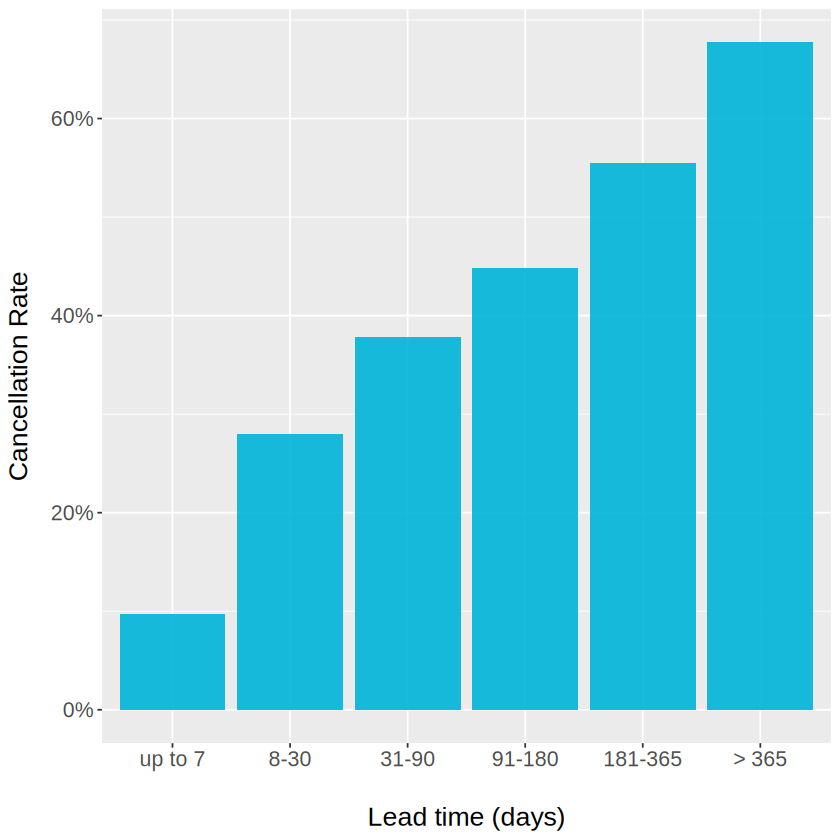

In [19]:
# Lead Time x Target
bins <- cut(hotel_new$lead_time,
            breaks = c(-1, 7, 30, 90, 180, 365, Inf),
            labels = c("up to 7", "8-30", "31-90", "91-180", "181-365", "> 365"))

rate <- aggregate(hotel_new$is_canceled == "Yes", by = list(bin = bins), FUN = mean)
names(rate)[2] <- "rate"

ggplot(rate, aes(x = bin, y = rate)) +
  geom_col(fill = "#00b4d8", alpha = 0.9) +
  scale_y_continuous(labels = scales::percent) +
  theme(text = element_text(size = 16)) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
    axis.title.y = element_text(margin = ggplot2::margin(r = 14))
  ) +
  xlab("Lead time (days)") +
  ylab("Cancellation Rate")

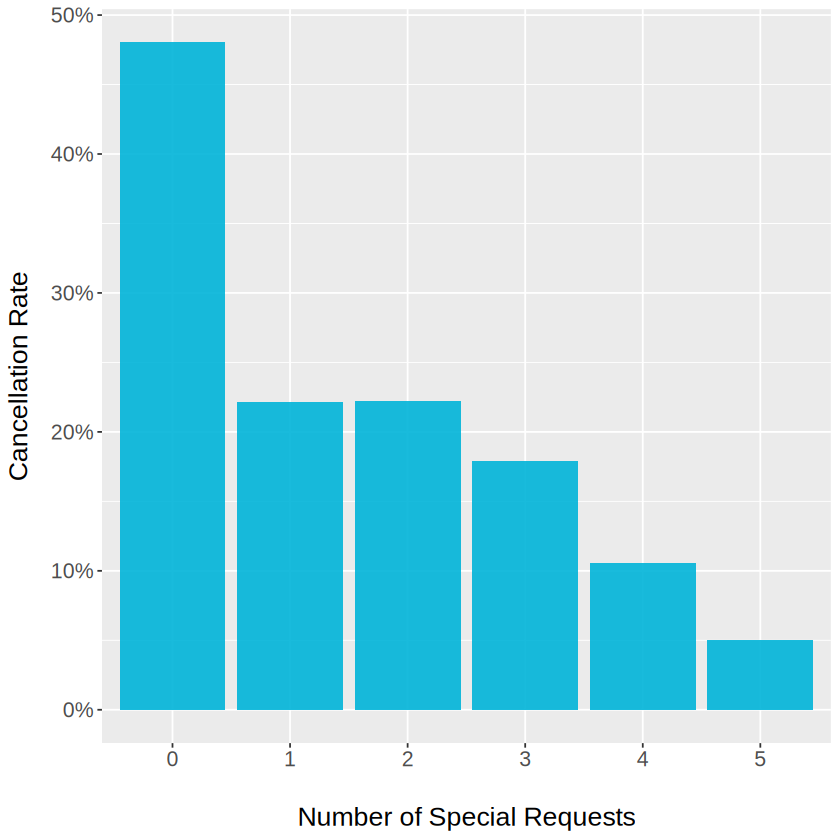

In [20]:
# Total of Special Requests x Target
bins <- factor(pmin(hotel_new$total_of_special_requests, 5))

rate <- aggregate(hotel_new$is_canceled == "Yes", by = list(bin = bins), FUN = mean)
names(rate)[2] <- "rate"

ggplot(rate, aes(x = bin, y = rate)) +
  geom_col(fill = "#00b4d8", alpha = 0.9) +
  scale_y_continuous(labels = scales::percent) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
    axis.title.y = element_text(margin = ggplot2::margin(r = 14))
  ) +
  xlab("Number of Special Requests") +
  ylab("Cancellation Rate")

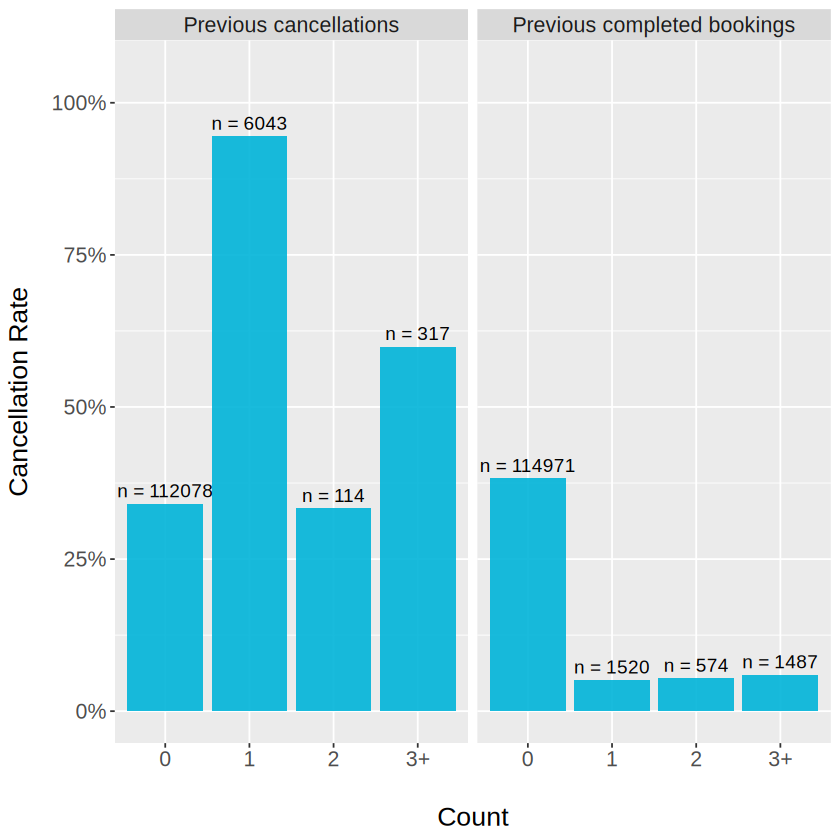

In [21]:
# Client History x Target
history_rate <- function(var, label) {
  bin <- factor(pmin(hotel_new[[var]], 3), levels = 0:3,
                labels = c("0", "1", "2", "3+"))
  tab <- aggregate(hotel_new$is_canceled == "Yes",
                   by = list(bin = bin), FUN = mean)
  names(tab)[2] <- "rate"
  tab <- merge(tab, as.data.frame(table(bin)))
  tab$variable <- label
  tab
}

history_data <- rbind(
  history_rate("previous_cancellations", "Previous cancellations"),
  history_rate("previous_bookings_not_canceled", "Previous completed bookings")
)

ggplot(history_data, aes(x = bin, y = rate)) +
  geom_col(fill = "#00b4d8", alpha = 0.9) +
  geom_text(aes(label = paste0("n = ", Freq)), vjust = -0.5, size = 4) +
  facet_wrap(~ variable) +
  scale_y_continuous(labels = scales::percent, limits = c(0, 1.05)) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
    axis.title.y = element_text(margin = ggplot2::margin(r = 14))
  ) +
  xlab("Count") +
  ylab("Cancellation Rate")

### Qualitative Variables

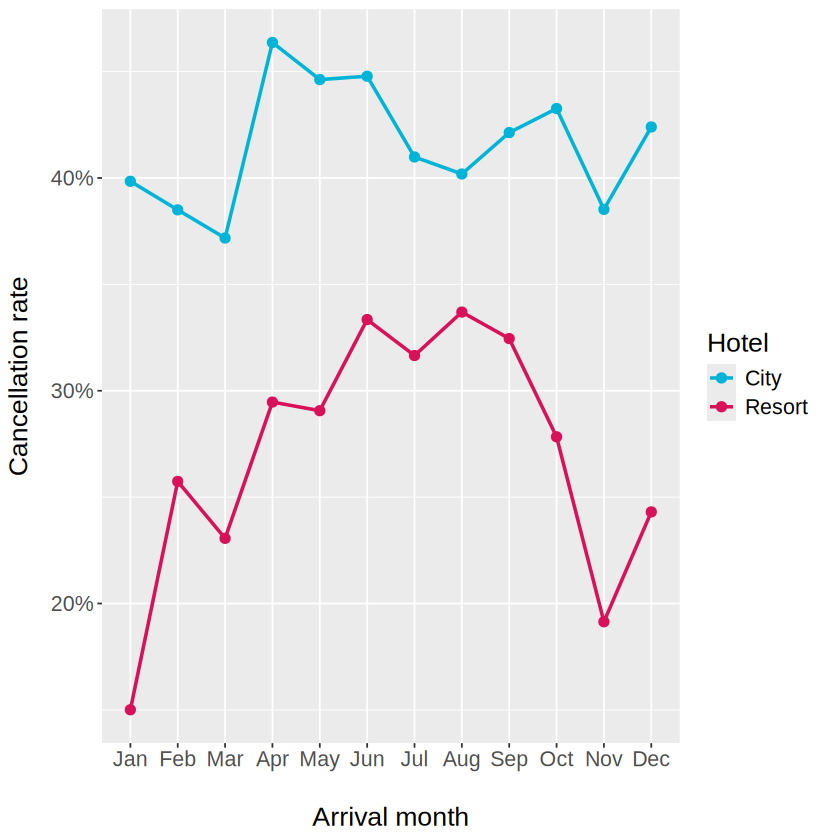

In [23]:
# Months (by Hotel Type) x Target
monthly_rate <- aggregate(hotel_new$is_canceled == "Yes",
                          by = list(month = hotel_new$arrival_date_month,
                                    hotel = hotel_new$hotel),
                          FUN = mean)
names(monthly_rate)[3] <- "rate"

# Sort months chronologically
monthly_rate$month <- factor(monthly_rate$month, levels = month.name)

ggplot(monthly_rate, aes(x = month, y = rate, color = hotel, group = hotel)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2.5) +
  scale_y_continuous(labels = scales::percent) +
  scale_x_discrete(labels = c("Jan", "Feb", "Mar", "Apr", "May", "Jun",
                              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec")) +
  scale_color_manual(values = c("City Hotel" = "#00b4d8", "Resort Hotel" = "#d81159"),
                     labels = c("City", "Resort")) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
    axis.title.y = element_text(margin = ggplot2::margin(r = 14))
  ) +
  xlab("Arrival month") +
  ylab("Cancellation rate") +
  labs(color = "Hotel")

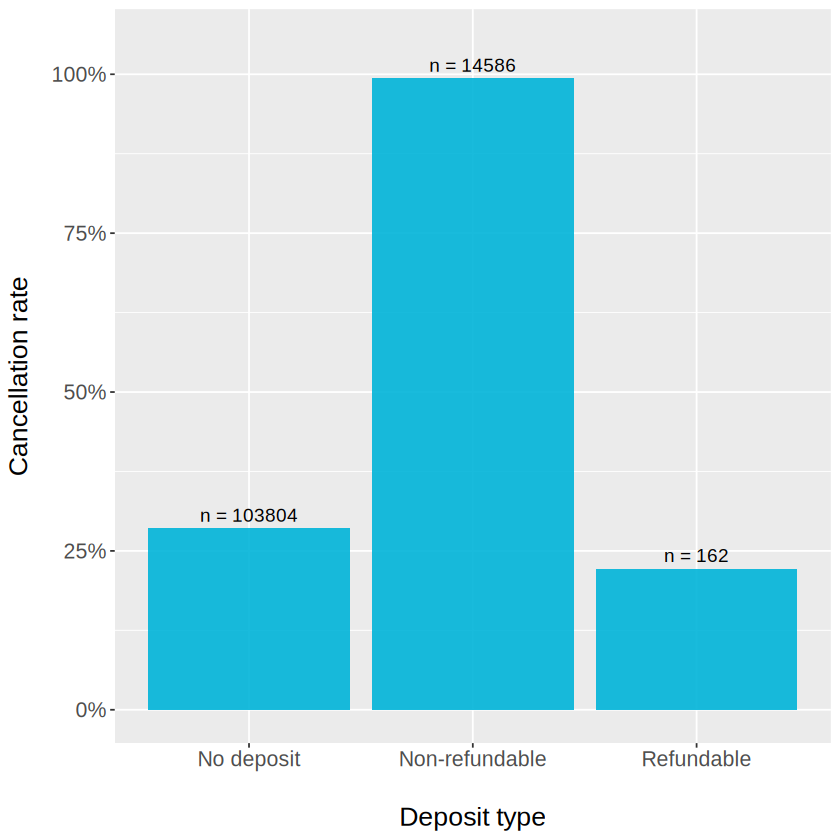

In [24]:
deposit_rate <- aggregate(hotel_new$is_canceled == "Yes",
                          by = list(deposit = hotel_new$deposit_type), FUN = mean)
names(deposit_rate)[2] <- "rate"
deposit_rate <- merge(deposit_rate, as.data.frame(table(deposit = hotel_new$deposit_type)))

ggplot(deposit_rate, aes(x = deposit, y = rate)) +
  geom_col(fill = "#00b4d8", alpha = 0.9) +
  geom_text(aes(label = paste0("n = ", Freq)), vjust = -0.5, size = 4) +
  scale_y_continuous(labels = scales::percent, limits = c(0, 1.05)) +
  scale_x_discrete(labels = c("No Deposit" = "No deposit",
                              "Non Refund" = "Non-refundable",
                              "Refundable" = "Refundable")) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
    axis.title.y = element_text(margin = ggplot2::margin(r = 14))
  ) +
  xlab("Deposit type") +
  ylab("Cancellation rate")

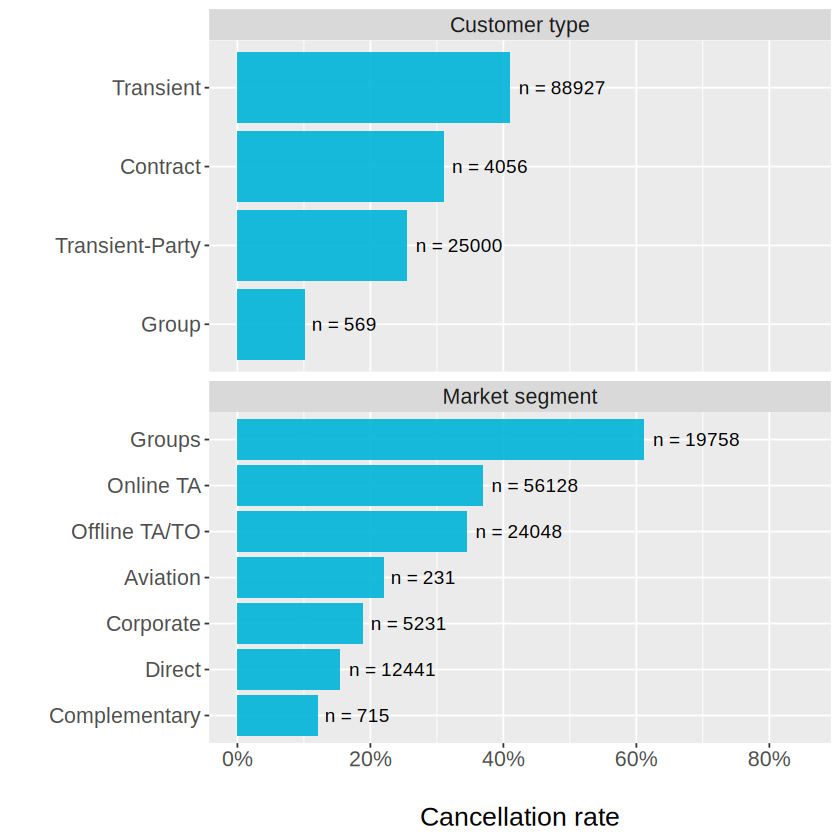

In [25]:
category_rate <- function(var, label) {
  tab <- aggregate(hotel_new$is_canceled == "Yes",
                   by = list(category = hotel_new[[var]]), FUN = mean)
  names(tab)[2] <- "rate"
  tab <- merge(tab, as.data.frame(table(category = hotel_new[[var]])))
  tab$variable <- label
  tab
}

profile_data <- rbind(
  category_rate("market_segment", "Market segment"),
  category_rate("customer_type", "Customer type")
)

ggplot(profile_data, aes(x = rate, y = reorder(category, rate))) +
  geom_col(fill = "#00b4d8", alpha = 0.9) +
  geom_text(aes(label = paste0("n = ", Freq)), hjust = -0.1, size = 4) +
  facet_wrap(~ variable, scales = "free_y", ncol = 1) +
  scale_x_continuous(labels = scales::percent, limits = c(0, 0.85)) +
    theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
  ) +
  xlab("Cancellation rate") +
  ylab(NULL)

## Models

In [26]:
set.seed(36)

# 70/30 split
train <- sample(nrow(hotel_new), 0.7 * nrow(hotel_new))
hotel_train <- hotel_new[train, ]
hotel_test <- hotel_new[-train, ]

prop.table(table(hotel_train$is_canceled))
prop.table(table(hotel_test$is_canceled))


       No       Yes 
0.6265997 0.3734003 


       No       Yes 
0.6293651 0.3706349 

### Naive Model

In [27]:
naive <- factor(rep("No", nrow(hotel_test)), levels = c("No", "Yes"))

confusionMatrix(data = naive, reference = hotel_test$is_canceled, positive = "Yes")

Confusion Matrix and Statistics

          Reference
Prediction    No   Yes
       No  22384 13182
       Yes     0     0
                                          
               Accuracy : 0.6294          
                 95% CI : (0.6243, 0.6344)
    No Information Rate : 0.6294          
    P-Value [Acc > NIR] : 0.5024          
                                          
                  Kappa : 0               
                                          
 Mcnemar's Test P-Value : <2e-16          
                                          
            Sensitivity : 0.0000          
            Specificity : 1.0000          
         Pos Pred Value :     NA          
         Neg Pred Value : 0.6294          
             Prevalence : 0.3706          
         Detection Rate : 0.0000          
   Detection Prevalence : 0.0000          
      Balanced Accuracy : 0.5000          
                                          
       'Positive' Class : Yes             
                  

### Logistic Regression

In [28]:
glm.fit <- glm(is_canceled ~ ., family = binomial, data = hotel_train)
summary(glm.fit)

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”



Call:
glm(formula = is_canceled ~ ., family = binomial, data = hotel_train)

Coefficients:
                                 Estimate Std. Error z value Pr(>|z|)    
(Intercept)                     0.1613638  0.1170721   1.378 0.168102    
hotelResort Hotel              -0.4288651  0.0252894 -16.958  < 2e-16 ***
lead_time                       0.0059688  0.0001288  46.328  < 2e-16 ***
arrival_date_monthFebruary      0.2113805  0.0583275   3.624 0.000290 ***
arrival_date_monthMarch         0.0036625  0.0565276   0.065 0.948340    
arrival_date_monthApril         0.1549305  0.0557432   2.779 0.005447 ** 
arrival_date_monthMay           0.1006284  0.0561201   1.793 0.072959 .  
arrival_date_monthJune         -0.0951729  0.0574572  -1.656 0.097638 .  
arrival_date_monthJuly         -0.3135299  0.0565625  -5.543 2.97e-08 ***
arrival_date_monthAugust       -0.2121540  0.0573117  -3.702 0.000214 ***
arrival_date_monthSeptember    -0.2366622  0.0594250  -3.983 6.82e-05 ***
arrival_date_monthOc

In [29]:
glm.probs <- predict(glm.fit, hotel_test, type = "response")
glm.pred <- factor(ifelse(glm.probs > 0.5, "Yes", "No"), levels = c("No", "Yes"))

result_glm <- confusionMatrix(data = glm.pred, reference = hotel_test$is_canceled, positive = "Yes")
result_glm

Confusion Matrix and Statistics

          Reference
Prediction    No   Yes
       No  20318  5045
       Yes  2066  8137
                                          
               Accuracy : 0.8001          
                 95% CI : (0.7959, 0.8042)
    No Information Rate : 0.6294          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.5506          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.6173          
            Specificity : 0.9077          
         Pos Pred Value : 0.7975          
         Neg Pred Value : 0.8011          
             Prevalence : 0.3706          
         Detection Rate : 0.2288          
   Detection Prevalence : 0.2869          
      Balanced Accuracy : 0.7625          
                                          
       'Positive' Class : Yes             
                  

### Linear Discriminant Analysis (LDA)

In [30]:
lda.fit <- lda(is_canceled ~ ., data = hotel_train)
lda.fit

Call:
lda(is_canceled ~ ., data = hotel_train)

Prior probabilities of groups:
       No       Yes 
0.6265997 0.3734003 

Group means:
    hotelResort Hotel lead_time arrival_date_monthFebruary
No          0.3810650  80.47801                 0.07103983
Yes         0.2526543 144.79685                 0.06002517
    arrival_date_monthMarch arrival_date_monthApril arrival_date_monthMay
No               0.08913633              0.08823247            0.09519414
Yes              0.07135250              0.10197825            0.10707716
    arrival_date_monthJune arrival_date_monthJuly arrival_date_monthAugust
No              0.08600165              0.1055597                0.1147330
Yes             0.10391454              0.1079162                0.1174686
    arrival_date_monthSeptember arrival_date_monthOctober
No                   0.08517471                0.09219408
Yes                  0.09181270                0.09645981
    arrival_date_monthNovember arrival_date_monthDecember
No       

In [31]:
lda.pred <- predict(lda.fit, hotel_test)

result_lda <- confusionMatrix(data = lda.pred$class,
                              reference = hotel_test$is_canceled,
                              positive = "Yes")
result_lda

Confusion Matrix and Statistics

          Reference
Prediction    No   Yes
       No  20721  5887
       Yes  1663  7295
                                         
               Accuracy : 0.7877         
                 95% CI : (0.7834, 0.792)
    No Information Rate : 0.6294         
    P-Value [Acc > NIR] : < 2.2e-16      
                                         
                  Kappa : 0.5129         
                                         
 Mcnemar's Test P-Value : < 2.2e-16      
                                         
            Sensitivity : 0.5534         
            Specificity : 0.9257         
         Pos Pred Value : 0.8144         
         Neg Pred Value : 0.7788         
             Prevalence : 0.3706         
         Detection Rate : 0.2051         
   Detection Prevalence : 0.2519         
      Balanced Accuracy : 0.7396         
                                         
       'Positive' Class : Yes            
                                      

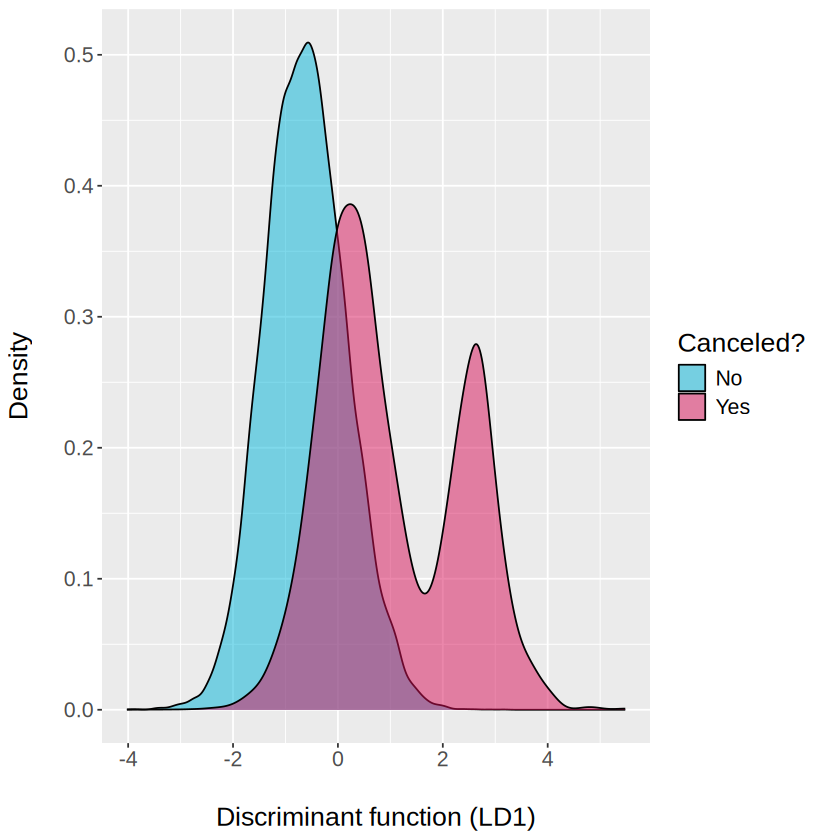

In [32]:
ggplot(data.frame(LD1 = lda.pred$x[, 1], canceled = hotel_test$is_canceled),
       aes(x = LD1, fill = canceled)) +
  geom_density(alpha = 0.5) +
  scale_fill_manual(values = c("No" = "#00b4d8", "Yes" = "#d81159"),
                    labels = c("No", "Yes")) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24)),
    axis.title.y = element_text(margin = ggplot2::margin(r = 14))
  ) +
  xlab("Discriminant function (LD1)") +
  ylab("Density") +
  labs(fill = "Canceled?")

### Random Forest

In [33]:
rf.fit <- randomForest(is_canceled ~ ., data = hotel_train, ntree = 300, importance = TRUE)
rf.fit


Call:
 randomForest(formula = is_canceled ~ ., data = hotel_train, ntree = 300,      importance = TRUE) 
               Type of random forest: classification
                     Number of trees: 300
No. of variables tried at each split: 4

        OOB estimate of  error rate: 13.35%
Confusion matrix:
       No   Yes class.error
No  47773  4226  0.08127079
Yes  6851 24136  0.22109272

In [34]:
rf.pred <- predict(rf.fit, hotel_test)

result_rf <- confusionMatrix(data = rf.pred,
                             reference = hotel_test$is_canceled,
                             positive = "Yes")
result_rf

Confusion Matrix and Statistics

          Reference
Prediction    No   Yes
       No  20561  3015
       Yes  1823 10167
                                          
               Accuracy : 0.864           
                 95% CI : (0.8604, 0.8675)
    No Information Rate : 0.6294          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.7029          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.7713          
            Specificity : 0.9186          
         Pos Pred Value : 0.8480          
         Neg Pred Value : 0.8721          
             Prevalence : 0.3706          
         Detection Rate : 0.2859          
   Detection Prevalence : 0.3371          
      Balanced Accuracy : 0.8449          
                                          
       'Positive' Class : Yes             
                  

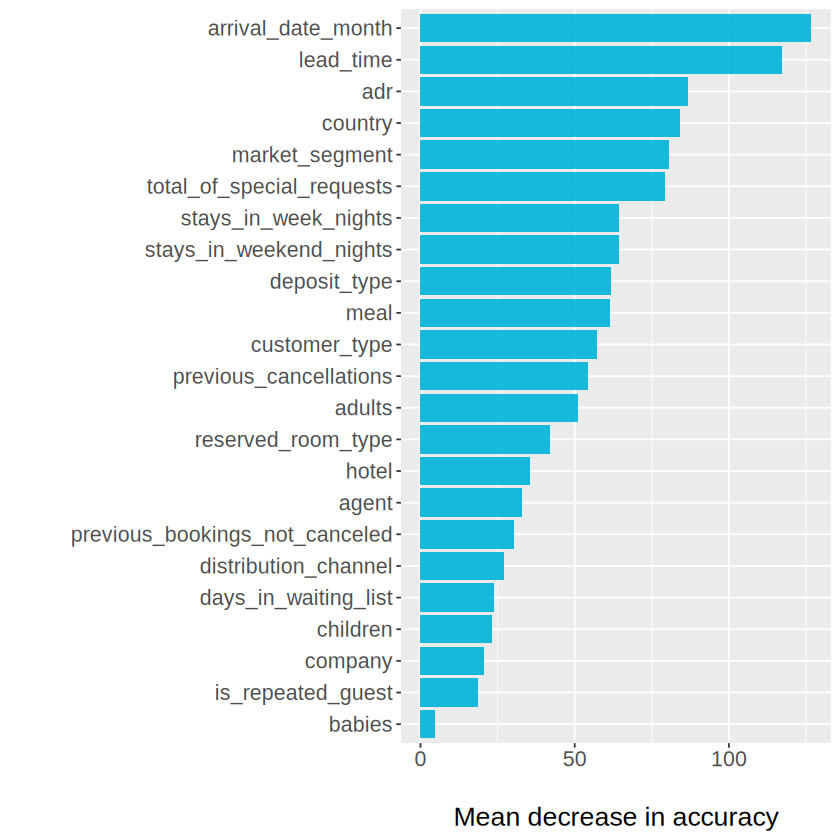

In [35]:
imp <- as.data.frame(importance(rf.fit))
imp$variable <- rownames(imp)

ggplot(imp, aes(x = MeanDecreaseAccuracy,
                y = reorder(variable, MeanDecreaseAccuracy))) +
  geom_col(fill = "#00b4d8", alpha = 0.9) +
  theme(
    text = element_text(size = 16),
    axis.title.x = element_text(margin = ggplot2::margin(t = 24))
  ) +
  xlab("Mean decrease in accuracy") +
  ylab(NULL)

# Results

In [36]:
## Comparison between models
metrics <- function(pred) {
  cm <- confusionMatrix(pred, hotel_test$is_canceled, positive = "Yes")
  c(cm$overall["Accuracy"],
    cm$byClass[c("Sensitivity", "Specificity", "Pos Pred Value")])
}

comparison <- rbind(
  "Logistic Regression" = metrics(glm.pred),
  "LDA"                 = metrics(lda.pred$class),
  "Random Forest"       = metrics(rf.pred)
)
round(comparison, 3)

,Accuracy,Sensitivity,Specificity,Pos Pred Value
Logistic Regression,0.800,0.617,0.908,0.798
LDA,0.788,0.553,0.926,0.814
Random Forest,0.864,0.771,0.919,0.848
